# **Connect to GEE**

In [ ]:
!pip install -q --upgrade --pre xee
!pip install -q -U geemap

In [ ]:
import ee

In [ ]:
ee.Authenticate()
ee.Initialize(
    project = 'ee-amirhosseinahrari',
    opt_url = 'https://earthengine-highvolume.googleapis.com'
)

# **Study Area**

In [ ]:
import geemap

In [ ]:
map = geemap.Map(basemap = 'SATELLITE')
map

Map(center=[0, 0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', transp…

In [ ]:
roi = map.draw_last_feature.geometry()
roi

ee.Geometry({
  "functionInvocationValue": {
    "functionName": "Feature.geometry",
    "arguments": {
      "feature": {
        "functionInvocationValue": {
          "functionName": "Feature",
          "arguments": {
            "geometry": {
              "functionInvocationValue": {
                "functionName": "GeometryConstructors.Polygon",
                "arguments": {
                  "coordinates": {
                    "constantValue": [
                      [
                        [
                          44.67041,
                          36.173357
                        ],
                        [
                          44.67041,
                          39.164141
                        ],
                        [
                          48.735352,
                          39.164141
                        ],
                        [
                          48.735352,
                          36.173357
                        ],
                        [
                          44.67041,
                          36.173357
                        ]
                      ]
                    ]
                  },
                  "geodesic": {
                    "constantValue": false
                  }
                }
              }
            }
          }
        }
      }
    }
  }
})

# **ERA5 Image Collection**

In [ ]:
era = (
    ee.ImageCollection("ECMWF/ERA5_LAND/DAILY_AGGR")
    .filterDate('2015','2026')
    .select(
        ['temperature_2m_min','temperature_2m_max'],
        ['temp_min','temp_max']
    )
)

In [ ]:
era.size()

In [ ]:
era.limit(5)

# **to Xarray**

In [ ]:
from xee import helpers
from shapely.geometry import shape
import xarray as xr

In [ ]:
grid = helpers.fit_geometry(
    geometry = shape(roi.getInfo()),
    grid_crs ='EPSG:4326',
    grid_scale  = (0.11, -0.11)
)

In [ ]:
ds = xr.open_dataset(
    era,
    engine = 'ee',
    **grid
)

In [ ]:
ds = ds.sortby('time') - 273.15

In [ ]:
ds['temp_min'].attrs['units'] = 'degC'
ds['temp_max'].attrs['units'] = 'degC'

In [ ]:
ds

<xarray.Dataset> Size: 35MB
Dimensions:   (time: 4018, y: 29, x: 38)
Coordinates:
  * time      (time) datetime64[ns] 32kB 2015-01-01 2015-01-02 ... 2025-12-31
  * y         (y) float64 232B 39.22 39.11 39.0 38.89 ... 36.36 36.25 36.14
  * x         (x) float64 304B 44.72 44.83 44.94 45.05 ... 48.57 48.68 48.79
Data variables:
    temp_min  (time, y, x) float32 18MB -3.253 -2.651 -1.382 ... -8.829 -8.897
    temp_max  (time, y, x) float32 18MB 8.481 9.2 9.571 ... 1.14 1.064 1.24

# **Heat Wave Analysis**

In [ ]:
!pip install -q xclim

In [ ]:
from xclim.indicators.atmos import heat_wave_index

In [ ]:
help(heat_wave_index)

In [ ]:
max_thr = ds['temp_max'].quantile(0.95, dim = 'time')
min_thr = ds['temp_min'].quantile(0.95, dim = 'time')

In [ ]:
hw_index = heat_wave_index(
    tasmax = ds['temp_max'],
    thresh = max_thr
)

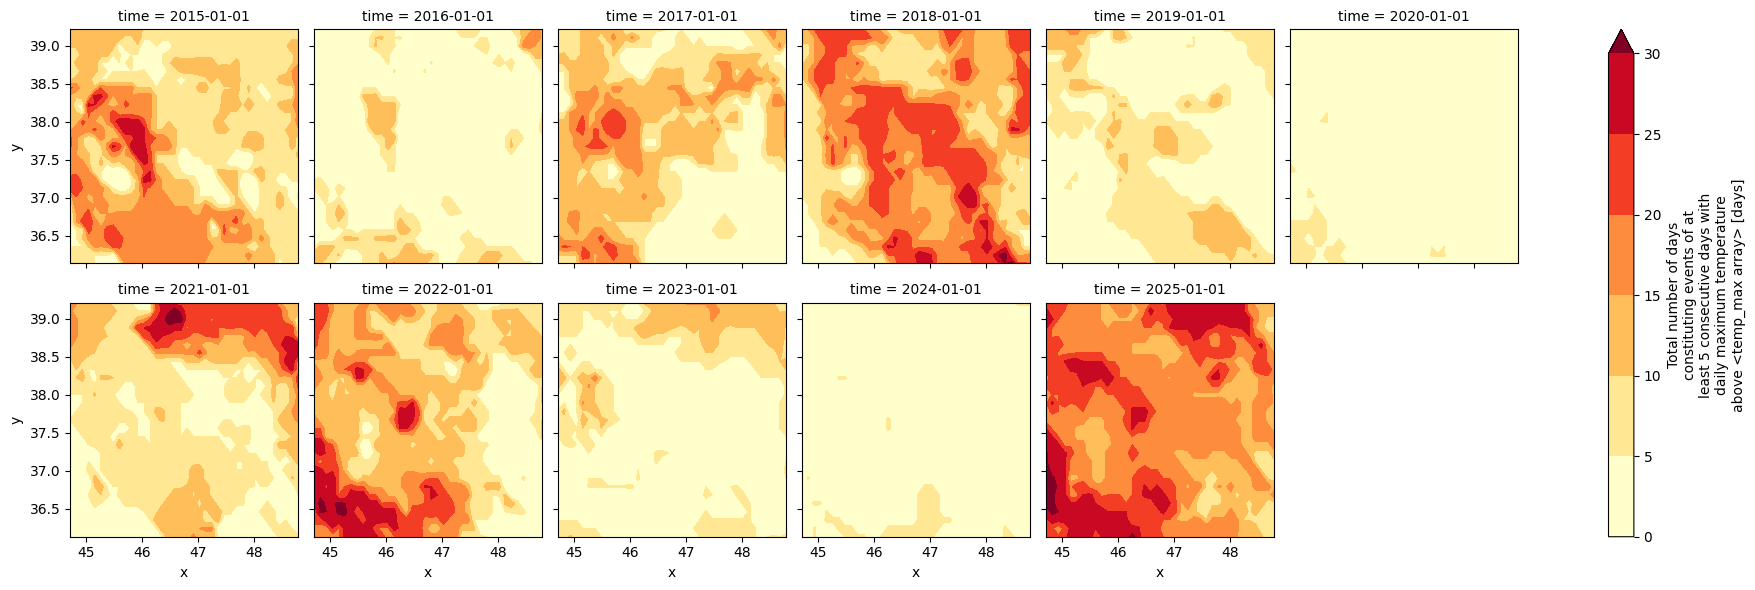

In [ ]:
hw_index['heat_wave_index'].plot.contourf(
    col = 'time',
    col_wrap = 6,
    cmap = 'YlOrRd',
    robust = True,
    levels = 7
)

In [ ]:
from xclim.indicators.atmos import heat_wave_total_length

In [ ]:
help(heat_wave_total_length)

Help on HEAT_WAVE_TOTAL_LENGTH in module xclim.indicators.atmos._temperature:

<xclim.indicators.atmos._temperature.HEAT_WAVE_TOTAL_LENGTH object>
    Heat wave total length

    Total length of heat waves. A heat wave occurs when daily minimum and maximum temperatures exceed given thresholds for a number of days.

    This indicator will check for missing values according to the method 'from_context'.
    Based on function :py:func:`~xclim.compute.generic.bivariate_spell_length_statistics`.
    With injected parameters: window_statistic=min, statistic=sum, min_gap=1, constrain=('>', '>=').

    Parameters
    ----------
    tasmin : str or DataArray
     Minimum surface temperature. Default: 'tasmin'. [Required units : [temperature]]
    tasmax : str or DataArray
     Maximum surface temperature. Default: 'tasmax'. [Required units : [temperature]]
    window : number
     Minimum length of a spell. Default: 3.
    condition : {'le', '!=', 'gt', '==', 'eq', 'ne', 'ge', 'lt', '<', '>=',

In [ ]:
hw_length = heat_wave_total_length(
    tasmax = ds['temp_max'] ,
    tasmin = ds['temp_min'],
    thresh_tasmax = max_thr,
    thresh_tasmin = min_thr
)

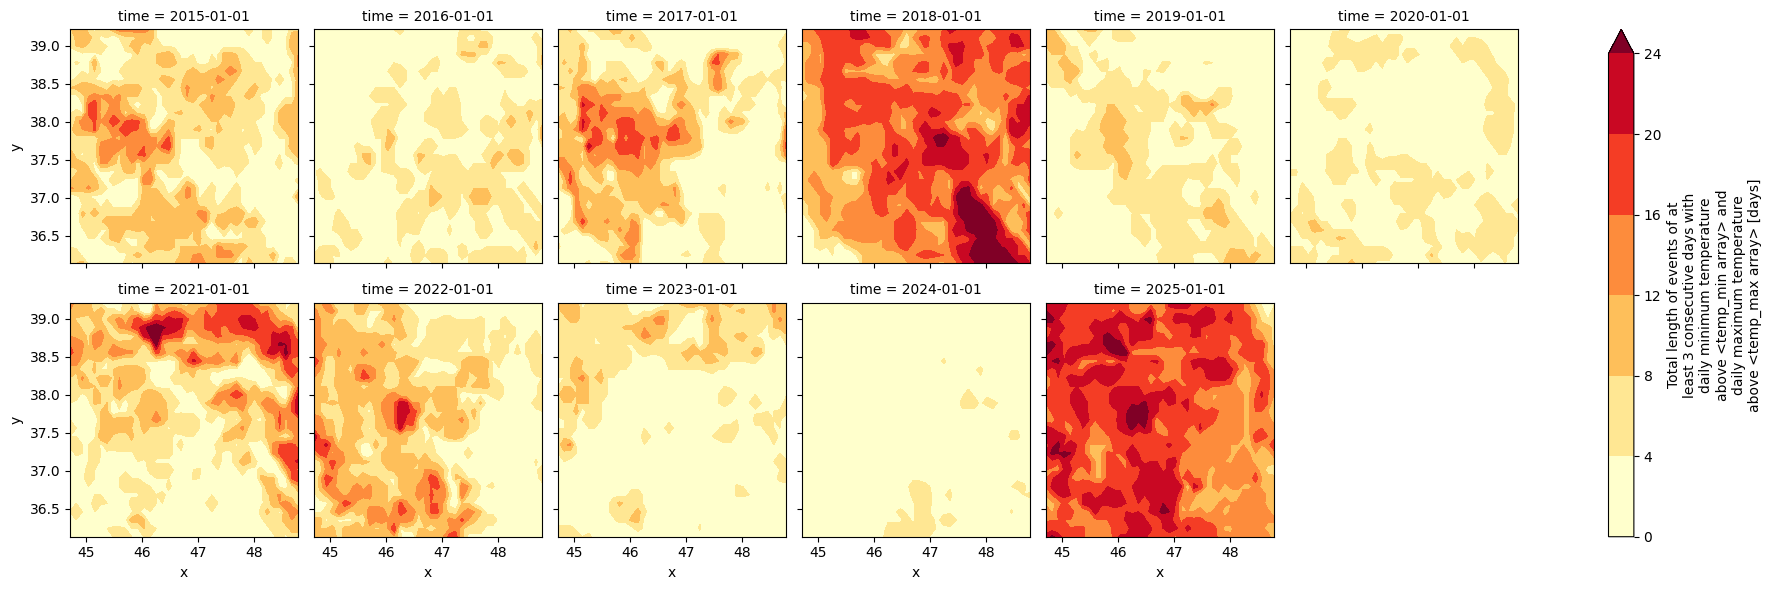

In [ ]:
hw_length['heat_wave_total_length'].plot.contourf(
    col = 'time',
    col_wrap = 6,
    cmap = 'YlOrRd',
    robust = True,
    levels = 7
)

In [ ]:
from xclim.indicators.atmos import heat_wave_max_length

In [ ]:
help(heat_wave_max_length)

Help on HEAT_WAVE_MAX_LENGTH in module xclim.indicators.atmos._temperature:

<xclim.indicators.atmos._temperature.HEAT_WAVE_MAX_LENGTH object>
    Heat wave maximum length

    Maximal duration of heat waves. A heat wave occurs when daily minimum and maximum temperatures exceed given thresholds for a number of days.

    This indicator will check for missing values according to the method 'from_context'.
    Based on function :py:func:`~xclim.compute.generic.bivariate_spell_length_statistics`.
    With injected parameters: window_statistic=min, statistic=max, min_gap=1, constrain=('>', '>=').

    Parameters
    ----------
    tasmin : str or DataArray
     Minimum surface temperature. Default: 'tasmin'. [Required units : [temperature]]
    tasmax : str or DataArray
     Maximum surface temperature. Default: 'tasmax'. [Required units : [temperature]]
    window : number
     Minimum length of a spell. Default: 3.
    condition : {'le', '!=', 'gt', '==', 'eq', 'ne', 'ge', 'lt', '<', '>=

In [ ]:
hw_max_length = heat_wave_max_length(
    tasmax = ds['temp_max'],
    tasmin =ds['temp_min'],
    thresh_tasmax = max_thr,
    thresh_tasmin =min_thr
)

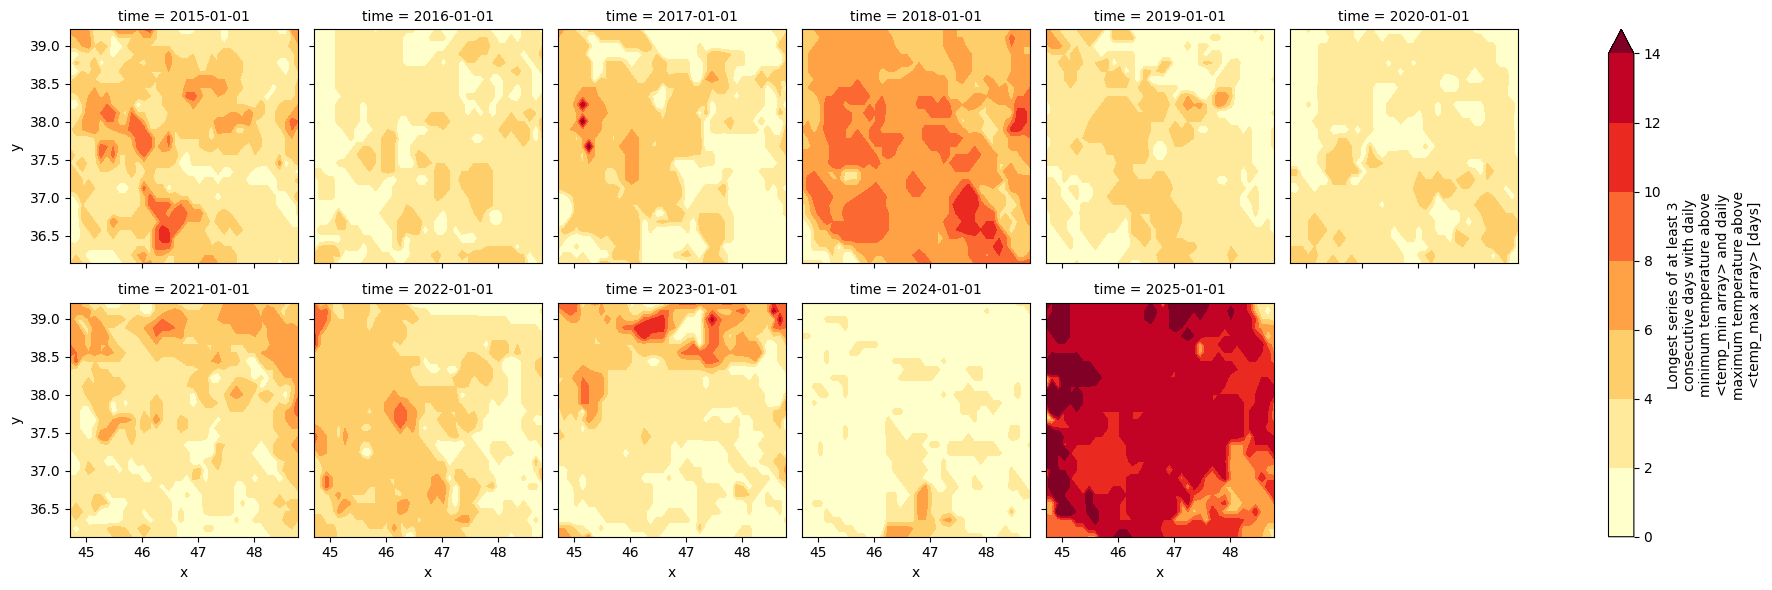

In [ ]:
hw_max_length['heat_wave_max_length'].plot.contourf(
    col = 'time',
    col_wrap = 6,
    cmap = 'YlOrRd',
    robust = True,
    levels =8
)